In [1]:
import matplotlib.pyplot as plt
import numpy as np

import tskit
import tszip

In [2]:
# md5sum-lite b88a7fc7d6dc0ec0abae153d3c5ce826
ts_file = "all-chr20p-filterNton23-truncate-0-0-0-mm0-post-processed-simplified-SDN-singletons-dated-metadata.trees.tsz"
ts = tszip.decompress(ts_file)
ts

#### Which ancestral haplotypes are suitable to constitute a reference panel?

In [3]:
hap_lens = ts.edges_right - ts.edges_left
edge_child_times = ts.nodes_time[ts.edges_child]
assert len(hap_lens) == len(edge_child_times)

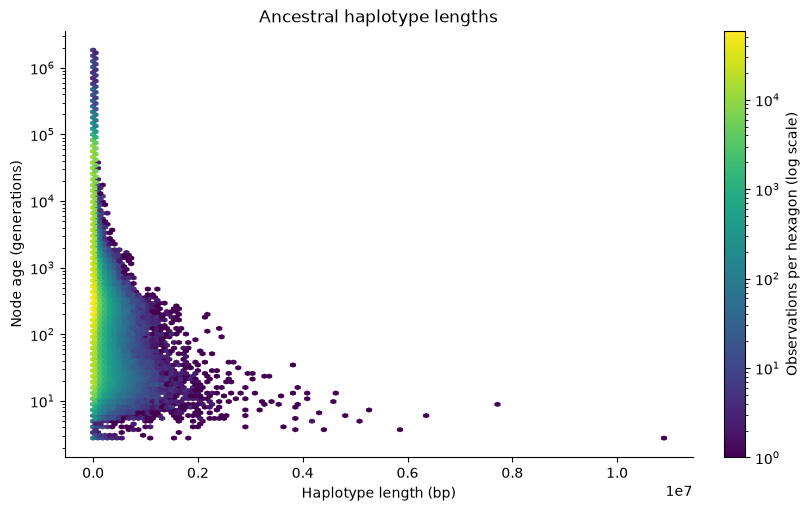

In [4]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
hb = ax.hexbin(
    hap_lens[edge_child_times > 0],
    edge_child_times[edge_child_times > 0],
    gridsize=120,
    yscale="log",
    bins="log",
    mincnt=1,
    cmap="viridis",
)
fig.colorbar(hb, ax=ax, label="Observations per hexagon (log scale)")
ax.set(
    title="Ancestral haplotype lengths",
    ylabel="Node age (generations)",
    xlabel="Haplotype length (bp)",
)
ax.set_yscale("log")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

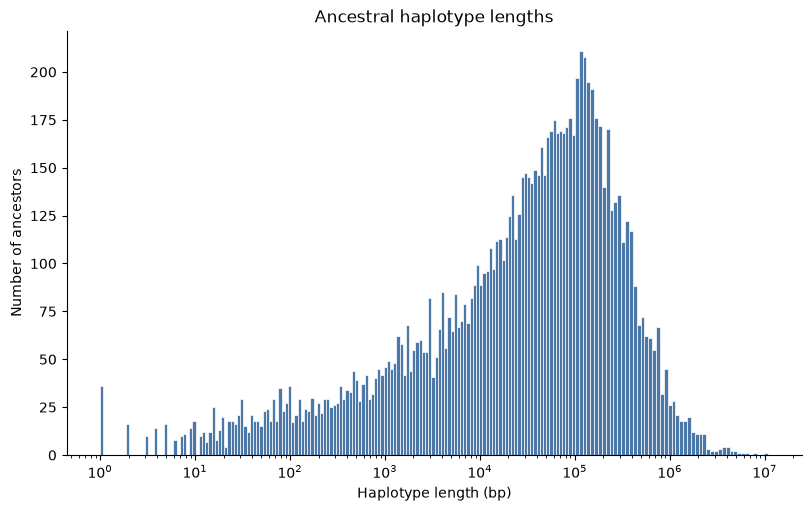

In [5]:
keep = np.logical_and(
    edge_child_times > 0,
    edge_child_times <= 10
)

bin_edges = np.concatenate((
    np.geomspace(hap_lens[keep].min(), 1e5, 150),
    np.geomspace(1e5, hap_lens[keep].max(), 51)[1:],
))

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.hist(
    hap_lens[keep],
    bins=bin_edges,
    color="#4C78A8",
    edgecolor="white",
    linewidth=0.5,
)
ax.set(
    title="Ancestral haplotype lengths",
    xlabel="Haplotype length (bp)",
    ylabel="Number of ancestors",
)
ax.set_xscale("log")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### Which genomic window is suitable?

In [17]:
bkpts = ts.breakpoints(as_array=True)
diversity = ts.diversity(windows=bkpts)

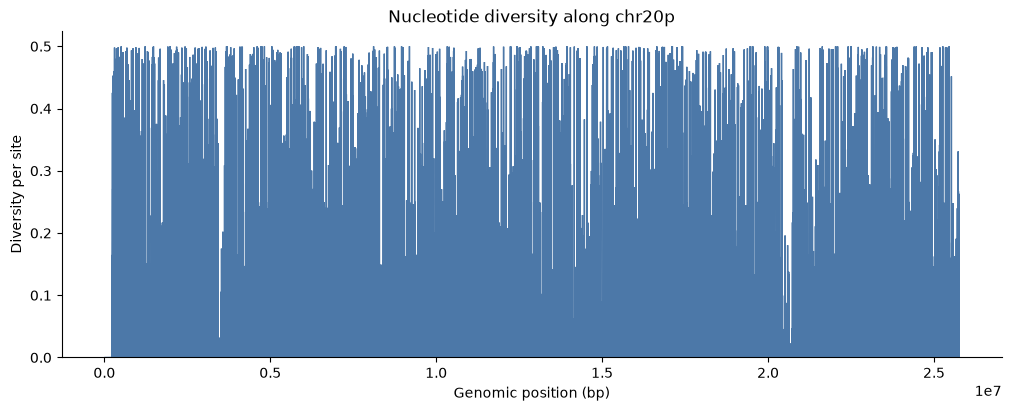

In [18]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.stairs(
    diversity[:-1],
    bkpts[:-1],
    color="#4C78A8",
    linewidth=1,
)
ax.set(
    title="Nucleotide diversity along chr20p",
    xlabel="Genomic position (bp)",
    ylabel="Diversity per site",
)
ax.spines[["top", "right"]].set_visible(False)
plt.show()